In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [7]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2','reject','w']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s','rejects','ws']

In [8]:
df_pythia= applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/other_output/rc/all0613_chargedrc.root', "MatchedTree"),'b!=0 and b!=-9 and pt>5 and reject<=0 and rejects<=0')

In [9]:
df_pythia.shape[0]

349521

In [10]:
w_array = np.unique(df_pythia['w'])

In [11]:
df_pythia_array = [ df_pythia[(df_pythia.pt>20) & (df_pythia.pt<25)],\
                    df_pythia[(df_pythia.pt>25) & (df_pythia.pt<30)],\
                    df_pythia[(df_pythia.pt>30) & (df_pythia.pt<40)] ]

In [12]:
rc_pythia_array = []
rc_err_pythia_array = []
for i in range(0, len(df_pythia_array)):
    rc_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b')[0])
    rc_err_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b')[1])

In [13]:
rc_pythia_array

[-0.38826026009188924, -0.39369460615230406, -0.3768098484983996]

In [14]:
rc_err_pythia_array

[0.011527121969105256, 0.012113454449615724, 0.01609186342325565]

In [15]:
df0 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [16]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8])
df_herwig = df[['pt','b_ch','w']]
df_herwig = applyCut(df_herwig, 'b_ch!=0 and b_ch!=-9 and pt>5')

In [17]:
df_herwig.shape[0]

2699840

In [18]:
w_array = np.unique(df_herwig['w'])

In [19]:
df_herwig_array = [ df_herwig[(df_herwig.pt>20) & (df_herwig.pt<25)],\
                    df_herwig[(df_herwig.pt>25) & (df_herwig.pt<30)],\
                    df_herwig[(df_herwig.pt>30) & (df_herwig.pt<40)] ]

In [20]:
rc_herwig_array = []
rc_err_herwig_array = []
for i in range(0, len(df_herwig_array)):
    rc_herwig_array.append(getRcAndErr(df_herwig_array[i], 'b_ch')[0])
    rc_err_herwig_array.append(getRcAndErr(df_herwig_array[i], 'b_ch')[1])

In [21]:
rc_herwig_array

[-0.36968295438279847, -0.3541739946295908, -0.3414549738707209]

In [22]:
rc_err_herwig_array

[0.00788790423739783, 0.011005639090995459, 0.008879922714931104]

In [23]:
df0 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_50pthat1000_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [24]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8])
df_pythia8 = df[['pt','b_ch','w']]
df_pythia8 = applyCut(df_pythia8, 'b_ch!=0 and b_ch!=-9 and pt>5')

In [25]:
df_pythia8.shape[0]

2396783

In [26]:
w_array = np.unique(df_pythia8['w'])

In [27]:
df_pythia8_array = [ df_pythia8[(df_pythia8.pt>20) & (df_pythia8.pt<25)],\
                    df_pythia8[(df_pythia8.pt>25) & (df_pythia8.pt<30)],\
                    df_pythia8[(df_pythia8.pt>30) & (df_pythia8.pt<40)] ]

In [28]:
rc_pythia8_array = []
rc_err_pythia8_array = []
for i in range(0, len(df_pythia8_array)):
    rc_pythia8_array.append(getRcAndErr(df_pythia8_array[i], 'b_ch')[0])
    rc_err_pythia8_array.append(getRcAndErr(df_pythia8_array[i], 'b_ch')[1])

In [29]:
rc_pythia8_array

[-0.3686137297129101, -0.3584602419537901, -0.36953000532066355]

In [30]:
rc_err_pythia8_array

[0.007056312261903326, 0.008763969085307896, 0.00658884920375993]

In [31]:
rc_nom = np.array([-0.32071319687798766,-0.31529244216709607,-0.30370721549050256])
rc_nom_err = np.array([0.016662090263359214, 0.01568386945752346, 0.02275573907877971])
rc_tow104 = np.array([-0.31277254848053226, -0.3122317907611789, -0.31378969220589203])
rc_tow104_err = np.array([0.017103057902613676, 0.016237920376146207, 0.023212088902109608])
rc_eff096 = np.array([-0.330978043127821, -0.31890810215713783, -0.3047232154729117])
rc_eff096_err = np.array([0.016707403954855676, 0.015261719434697044, 0.02401862482411803])
rc_hadcorr05 = np.array([-0.32664454439280016, -0.30906019968768633, -0.29790311449786966])
rc_hadcorr05_err = np.array([0.01650647443030242, 0.015705708625763787, 0.02275965678553469])
rc_new = np.array([-0.31280097208127344, -0.3166950650286405, -0.3014920977065607])
rc_new_err = np.array([0.004843824846401325, 0.005331678717212091, 0.005230663600817661])

In [32]:
rc_stat_err = np.array([0.0032768538529201106, 0.006688613461258784, 0.012425797722755979])
rc_nonclosure_err = np.array([0.00024143, -0.00763721, -0.00973332])

In [33]:
rc_random = np.array([-0.22518997953719813, -0.21441642135412523, -0.2129313872595826])
rc_random_err = np.array([0.002925290181545458, 0.006160481432193258, 0.01141150183243689])

In [34]:
sys_err = np.sqrt(rc_nom_err**2+(rc_tow104-rc_nom)**2+(rc_eff096-rc_nom)**2+(rc_hadcorr05-rc_nom)**2+(rc_new-rc_nom)**2+(rc_nonclosure_err)**2)

In [35]:
rc_nom-sys_err

array([-0.34403462, -0.33446428, -0.33116344])

In [36]:
rc_nom+sys_err

array([-0.29739178, -0.2961206 , -0.27625099])

In [37]:
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
plt.rcParams['font.family'] = 'arial'
plt.rcParams['axes.unicode_minus'] = False

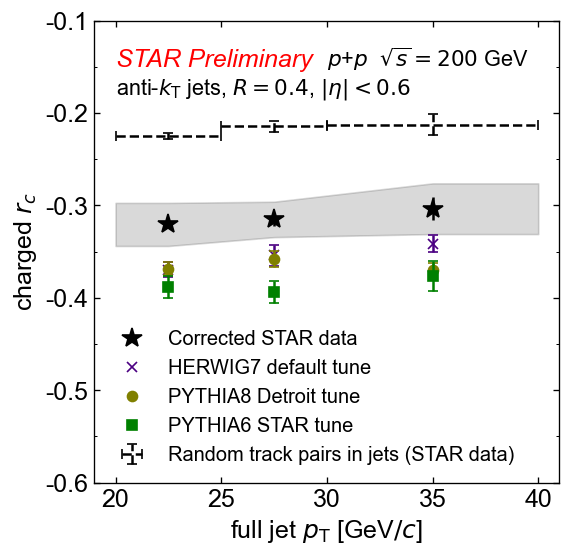

In [54]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_nom, yerr=rc_stat_err, capsize=0, ls='none', color='k')
nom = plt.plot([22.5, 27.5, 35], rc_nom, ls='none', marker='*', markersize=12, label='Corrected STAR data', color='k')[0]
plt.fill_between([20, 22.5, 27.5, 35, 40], [-0.34403462,-0.34403462, -0.33446428, -0.33116344, -0.33116344], [-0.29739178, -0.29739178, -0.2961206 , -0.27625099, -0.27625099], alpha=0.15, color='k')
#first_legend = plt.legend(handles=[eb1], fontsize=12, loc='lower left')
#plt.gca().add_artist(first_legend)
plt.errorbar([22.5, 27.5, 35], rc_herwig_array, yerr=rc_err_herwig_array, capsize=3, color='indigo', ls='none')
herwig = plt.plot([22.5, 27.5, 35], rc_herwig_array, color='indigo', ls='none', label='HERWIG7 default tune', marker='x')[0]
plt.errorbar([22.5, 27.5, 35], rc_pythia8_array, yerr=rc_err_pythia8_array, capsize=3, color='olive', ls='none')
pythia8 = plt.plot([22.5, 27.5, 35], rc_pythia8_array, color='olive', ls='none', label='PYTHIA8 Detroit tune', marker='o')[0]
plt.errorbar([22.5, 27.5, 35], rc_pythia_array, yerr=rc_err_pythia_array, capsize=3, color='g', ls='none')
pythia = plt.plot([22.5, 27.5, 35], rc_pythia_array, color='g', ls='none', label='PYTHIA6 STAR tune', marker='s')[0]
eb1=plt.errorbar([22.5, 27.5, 35], rc_random, xerr=[2.5,2.5,5], yerr=rc_random_err, ls='none', label='Random track pairs in jets (STAR data)', color='k', capsize=3)
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.text(20,-0.15, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(30, -0.15,'$p$+$p$  $\sqrt{s}=200$ GeV', fontsize=13)
plt.text(20, -0.18, 'anti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(handles=[nom, herwig, pythia8, pythia, eb1], fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.savefig('rc_vs_pt_hp24.png', bbox_inches='tight')
#plt.savefig('rc_vs_pt_hp24.pdf', bbox_inches='tight')

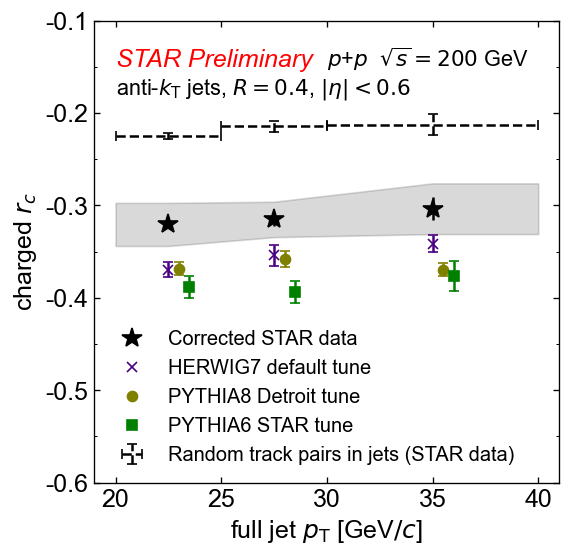

In [60]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_nom, yerr=rc_stat_err, capsize=0, ls='none', color='k')
nom = plt.plot([22.5, 27.5, 35], rc_nom, ls='none', marker='*', markersize=12, label='Corrected STAR data', color='k')[0]
plt.fill_between([20, 22.5, 27.5, 35, 40], [-0.34403462,-0.34403462, -0.33446428, -0.33116344, -0.33116344], [-0.29739178, -0.29739178, -0.2961206 , -0.27625099, -0.27625099], alpha=0.15, color='k')
#first_legend = plt.legend(handles=[eb1], fontsize=12, loc='lower left')
#plt.gca().add_artist(first_legend)
plt.errorbar([22.5, 27.5, 35], rc_herwig_array, yerr=rc_err_herwig_array, capsize=3, color='indigo', ls='none')
herwig = plt.plot([22.5, 27.5, 35], rc_herwig_array, color='indigo', ls='none', label='HERWIG7 default tune', marker='x')[0]
plt.errorbar([23, 28, 35.5], rc_pythia8_array, yerr=rc_err_pythia8_array, capsize=3, color='olive', ls='none')
pythia8 = plt.plot([23, 28, 35.5], rc_pythia8_array, color='olive', ls='none', label='PYTHIA8 Detroit tune', marker='o')[0]
plt.errorbar([23.5, 28.5, 36], rc_pythia_array, yerr=rc_err_pythia_array, capsize=3, color='g', ls='none')
pythia = plt.plot([23.5, 28.5, 36], rc_pythia_array, color='g', ls='none', label='PYTHIA6 STAR tune', marker='s')[0]
eb1=plt.errorbar([22.5, 27.5, 35], rc_random, xerr=[2.5,2.5,5], yerr=rc_random_err, ls='none', label='Random track pairs in jets (STAR data)', color='k', capsize=3)
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.text(20,-0.15, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(30, -0.15,'$p$+$p$  $\sqrt{s}=200$ GeV', fontsize=13)
plt.text(20, -0.18, 'anti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(handles=[nom, herwig, pythia8, pythia, eb1], fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.savefig('rc_vs_pt_hp24.png', bbox_inches='tight')
plt.savefig('rc_vs_pt_shifted.pdf', bbox_inches='tight')